# Experimento — Padrões de prompt e aferição de manutenibilidade por LLMs

**TCC:** Influência de Padrões de Prompt na Avaliação da Manutenibilidade de Software com Modelos de Linguagem de Grande Escala
**Autor:** Guilherme Storch · **Orientador:** Prof. Hilmer Rodrigues Neri · UnB/FCTE

Este notebook implementa o Capítulo 5 (Planejamento do Experimento). Cada seção corresponde a uma etapa do processo de experimentação (WOHLIN et al., 2024) e grava suas saídas em `data/`, para que qualquer pessoa reproduza os resultados a partir deste repositório.

| Seção | Conteúdo | Gate |
|---|---|---|
| 0 | Configuração e rastreabilidade | GATE 2 |
| 1 | Corpus, funil de exclusão, classificação por tipo e amostragem | GATE 2 |
| 2 | Medição de referência (SonarQube → Q-Rapids, MSG, SQALE) | GATE 2 · *próxima parte* |
| 3–7 | Prompts, aleatorização, piloto, execução, validação | GATE 3 |
| 8–11 | Análise estatística e empacotamento | GATE 4 |

## 0. Configuração e rastreabilidade

Registra versões, semente e regras. Todas as regras que afetam a seleção dos dados ficam em `src/config.py`.

In [1]:
import sys, json, platform, subprocess
from datetime import datetime, timezone
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import tree_sitter

from src import config as C
from src import corpus as K

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
for d in (C.PROCESSED_DIR, C.OUTPUTS_DIR, C.FIGURAS_DIR, C.REPOS_DIR):
    d.mkdir(parents=True, exist_ok=True)

Matplotlib is building the font cache; this may take a moment.


In [2]:
def versao(pacote):
    from importlib.metadata import version, PackageNotFoundError
    try:
        return version(pacote)
    except PackageNotFoundError:
        return None

ambiente = {
    "gerado_em": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "python": platform.python_version(),
    "sistema": platform.platform(),
    "git": subprocess.run(["git", "--version"], capture_output=True, text=True).stdout.strip(),
    "seed": C.SEED,
    "pacotes": {p: versao(p) for p in ["pandas", "numpy", "matplotlib", "tree-sitter", "tree-sitter-java"]},
    "regras": {
        "diretorios_excluidos": C.DIRETORIOS_EXCLUIDOS,
        "padroes_nome_teste": C.PADROES_NOME_TESTE,
        "arquivos_estruturais": sorted(C.ARQUIVOS_ESTRUTURAIS),
        "tipos_excluidos": sorted(C.TIPOS_EXCLUIDOS),
        "loc_min": C.LOC_MIN, "loc_max": C.LOC_MAX,
        "k_por_estrato": C.K_POR_ESTRATO,
    },
}
(C.OUTPUTS_DIR / "ambiente.json").write_text(json.dumps(ambiente, indent=2, ensure_ascii=False))
print(json.dumps({k: ambiente[k] for k in ["gerado_em", "python", "seed", "pacotes"]}, indent=2))

{
  "gerado_em": "2026-10-20T04:45:49+00:00",
  "python": "3.9.6",
  "seed": 42,
  "pacotes": {
    "pandas": "2.3.3",
    "numpy": "2.0.2",
    "matplotlib": "3.9.4",
    "tree-sitter": "0.23.2",
    "tree-sitter-java": "0.23.5"
  }
}


## 1. Seleção do corpus

### 1.1 Repositórios fixados

Os seis repositórios vêm dos estudos da revisão estruturada (Seção 5.5). Cada um é fixado na release estável mais recente na data do levantamento, e o commit é conferido após o clone. Assim, o corpus não muda se os projetos evoluírem.

In [3]:
repos = K.carregar_repos()
verificacao = pd.DataFrame([
    K.preparar_repositorio(r.projeto, r.url, r.release, r.commit) for r in repos.itertuples()
])
corpus_repos = repos.merge(verificacao[["projeto", "commit_obtido", "confere", "data_commit"]], on="projeto")
corpus_repos.to_csv(C.PROCESSED_DIR / "corpus_repos.csv", index=False)

assert corpus_repos["confere"].all(), "Algum repositório não está no commit esperado."
corpus_repos[["projeto", "linguagem", "release", "data_commit", "commit", "confere", "estudo_origem"]]

,projeto,linguagem,release,data_commit,commit,confere,estudo_origem
0,django,python,6.1.2,2026-10-06,2212534bae393714e1e51db2341d4fd5545e19f6,True,Sun et al. (2026)
1,flask,python,3.1.3,2026-02-18,22d924701a6ae2e4cd01e9a15bbaf3946094af65,True,Liu et al. (2025b)
2,pandas,python,v3.0.6,2026-09-17,2905718b126579d2cf0fe5bae05bd75facb67d77,True,Liu et al. (2025b)
3,guava,java,v33.7.2,2026-09-29,666338cc49d5686c07e3e4d17f0aa1cec25a2be6,True,Nunes et al. (2025)
4,conductor,java,v3.32.5,2026-09-24,49f972398e533441ba851e2b578a8b96d748a770,True,Ouédraogo et al. (2026)
5,apollo,java,v3.0.0,2026-10-03,00d307b0044e2c55c5390ffdf5658f079ee9b187,True,Nunes et al. (2025)


### 1.2 Inventário e classificação por tipo

Cada arquivo da linguagem do repositório é listado e, se não for excluído pelo caminho, classificado pelo conteúdo predominante:

| Linguagem | Critério | Tipo |
|---|---|---|
| Java | declaração top-level `class` | `classe` |
| Java | `interface` | `interface` |
| Java | `enum` ou `record` | `enum_record` |
| Java | `@interface` | `anotacao` (excluído) |
| Python | só classes no nível do módulo | `classe` |
| Python | só funções no nível do módulo | `modulo_funcoes` |
| Python | classes e funções | `misto` |
| Python | nenhuma definição | `sem_definicoes` (excluído) |

Python é analisado com `ast` (biblioteca padrão) e Java com tree-sitter. Arquivos sem nenhuma função ou método com corpo são excluídos, porque a medida de complexidade por função do Q-Rapids não se aplica a eles. O LOC aqui é a contagem de linhas não vazias e serve só para descrever o corpus. O `ncloc` oficial vem do SonarQube na Seção 2.

In [17]:
inventario = pd.concat(
    [K.inventariar(r.projeto, r.linguagem) for r in repos.itertuples()], ignore_index=True
)
inventario.to_csv(C.PROCESSED_DIR / "inventario.csv", index=False)
print(f"Arquivos encontrados: {len(inventario):,} | elegíveis: {inventario['elegivel'].sum():,}")

Arquivos encontrados: 9,980 | elegíveis: 2,989


### 1.3 Funil de exclusão

Cada arquivo excluído recebe **um** motivo: o primeiro critério que ele atende, na ordem da tabela. A tabela justifica, com números, a passagem do total de arquivos para o conjunto elegível.

In [7]:
funil = K.funil(inventario)
funil.to_csv(C.OUTPUTS_DIR / "funil_exclusao.csv")
funil

projeto,apollo,conductor,django,flask,guava,pandas,total
motivo,,,,,,,
total_encontrado,767,1470,2919,83,3227,1514,9980
arquivo_estrutural,2,0,656,16,48,184,906
teste,238,512,1551,37,1810,1012,5160
documentacao_exemplo,0,1,4,8,0,5,18
script_build_benchmark,8,0,8,0,128,74,218
migracao_locale,0,0,124,0,0,0,124
erro_parse,0,0,4,0,0,1,5
tipo_sem_definicoes,0,0,20,4,0,16,40
tipo_anotacao,7,19,0,0,62,0,88


### 1.4 Distribuição dos elegíveis por repositório × tipo

Esses são os estratos da amostragem e da análise estratificada (Seção 9).

In [8]:
elegiveis = inventario[inventario["elegivel"]].copy()
distribuicao = elegiveis.pivot_table(index="projeto", columns="tipo", values="caminho",
                                     aggfunc="count", fill_value=0, margins=True, margins_name="total")
distribuicao.to_csv(C.OUTPUTS_DIR / "distribuicao_tipos.csv")
distribuicao

tipo,classe,enum_record,interface,misto,modulo_funcoes,total
projeto,,,,,,
apollo,424,0,2,0,0,426
conductor,755,3,18,0,0,776
django,288,0,0,126,105,519
flask,6,0,0,10,2,18
guava,1006,14,10,0,0,1030
pandas,39,0,0,92,89,220
total,2518,17,30,228,196,2989


In [7]:
pequenos = elegiveis.groupby(["projeto", "tipo"]).size().loc[lambda s: s < 10]
print("Estratos com menos de 10 arquivos (decidir: manter, agrupar ou excluir):")
pequenos.to_frame("N")

Estratos com menos de 10 arquivos (decidir: manter, agrupar ou excluir):


N
projeto   tipo             
apollo    interface       2
conductor enum_record     3
flask     classe          6
          modulo_funcoes  2

### 1.5 Tamanho dos arquivos (LOC)

A distribuição orienta a decisão sobre um corte de tamanho, que será tomada no piloto. Excluir arquivos grandes reduz custo e contexto, mas também retira os arquivos que tendem a ser menos manuteníveis (ameaça à validade externa).

In [9]:
loc = (elegiveis.groupby("projeto")["loc"]
       .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95])
       .rename(columns={"count": "n"}).round(0).astype(int))
for corte in (500, 800, 1000, 2000):
    loc[f">{corte}"] = elegiveis.groupby("projeto")["loc"].apply(lambda s: int((s > corte).sum()))
loc.to_csv(C.OUTPUTS_DIR / "loc_por_projeto.csv")
loc

,n,mean,std,min,25%,50%,75%,90%,95%,max,>500,>800,>1000,>2000
projeto,,,,,,,,,,,,,,
apollo,426,105,102,22,46,72,119,231,302,996,5,1,0,0
conductor,776,175,291,18,49,90,178,386,547,3457,51,23,13,4
django,519,224,338,3,51,113,272,508,652,2768,55,16,14,5
flask,18,391,324,55,166,262,519,829,958,1253,6,2,1,0
guava,1030,304,416,16,77,155,366,722,994,4286,195,83,50,12
pandas,220,913,1608,22,167,422,950,2171,3034,14340,92,63,53,26


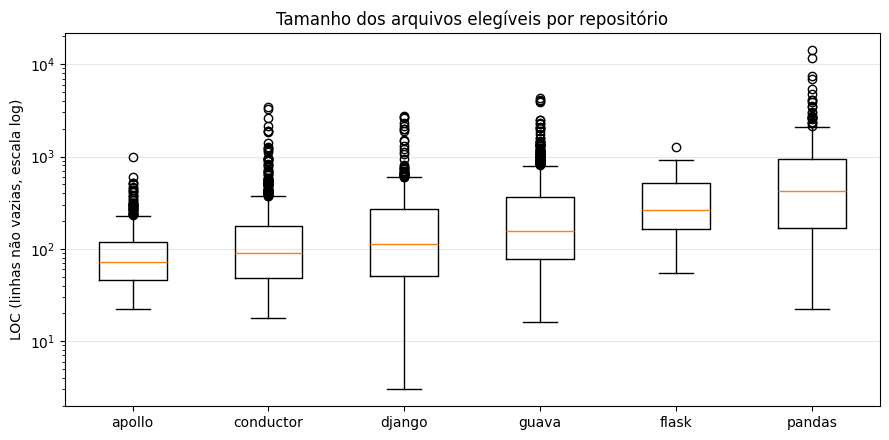

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ordem = loc.sort_values("50%").index.tolist()
ax.boxplot([elegiveis.loc[elegiveis["projeto"] == p, "loc"] for p in ordem], showfliers=True)
ax.set_xticks(range(1, len(ordem) + 1), ordem)
ax.set_yscale("log")
ax.set_ylabel("LOC (linhas não vazias, escala log)")
ax.set_title("Tamanho dos arquivos elegíveis por repositório")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(C.FIGURAS_DIR / "loc_por_projeto.png", dpi=200)
plt.show()

### 1.6 Cenários de tamanho de amostra

A amostragem sorteia até *k* arquivos por estrato (repositório × tipo), com semente fixa. Um *k* fixo impede que os repositórios grandes (Guava, Conductor) dominem a amostra. Estratos menores que *k* entram inteiros. Cada arquivo gera 18 chamadas (3 prompts × 3 LLMs × 2 modelos) por repetição.

In [11]:
cenarios = K.tamanho_amostra_por_k(elegiveis, C.K_CANDIDATOS)
total = cenarios.loc[("TOTAL", "")]
resumo = pd.DataFrame({
    "arquivos": total.drop("N"),
    "chamadas_LLM (r=1)": total.drop("N") * 18,
    "chamadas_LLM (r=3)": total.drop("N") * 18 * 3,
})
cenarios.to_csv(C.OUTPUTS_DIR / "cenarios_amostra_k.csv")
display(cenarios)
resumo

N  k=10  k=20  k=30  k=50
projeto   tipo                                        
apollo    classe           424    10    20    30    50
          interface          2     2     2     2     2
conductor classe           755    10    20    30    50
          enum_record        3     3     3     3     3
          interface         18    10    18    18    18
django    classe           288    10    20    30    50
          misto            126    10    20    30    50
          modulo_funcoes   105    10    20    30    50
flask     classe             6     6     6     6     6
          misto             10    10    10    10    10
          modulo_funcoes     2     2     2     2     2
guava     classe          1006    10    20    30    50
          enum_record       14    10    14    14    14
          interface         10    10    10    10    10
pandas    classe            39    10    20    30    39
          misto             92    10    20    30    50
          modulo_funcoes    89    10    20    30    50
TOTAL                     2989   143   245   335   504

,arquivos,chamadas_LLM (r=1),chamadas_LLM (r=3)
k=10,143,2574,7722
k=20,245,4410,13230
k=30,335,6030,18090
k=50,504,9072,27216


### 1.7 Amostra

Gerada somente depois de `K_POR_ESTRATO` ser definido em `src/config.py` (decisão com o orientador, confirmada pelo cálculo de poder no piloto).

In [13]:
if C.K_POR_ESTRATO is None:
    print("K_POR_ESTRATO ainda não definido: amostra não gerada.")
else:
    amostra = K.amostrar(elegiveis, C.K_POR_ESTRATO)
    amostra.to_csv(C.PROCESSED_DIR / "corpus.csv", index=False)
    print(f"Amostra: {len(amostra)} arquivos")
    display(amostra.groupby(["projeto", "tipo"]).size().unstack(fill_value=0))

K_POR_ESTRATO ainda não definido: amostra não gerada.


### 1.8 Pendências para o orientador (geradas a partir dos dados)

In [16]:
print(f"1. Corpus: {len(inventario):,} arquivos encontrados → {len(elegiveis):,} elegíveis "
      f"(funil em data/outputs/funil_exclusao.csv).")
print(f"2. Estratos com < 10 arquivos: {len(pequenos)} → manter, agrupar ou excluir?")
print("3. k por estrato: cenários em data/outputs/cenarios_amostra_k.csv →",
      ", ".join(f"k={k}: {int(total[f'k={k}'])} arquivos" for k in C.K_CANDIDATOS))
mx = int(elegiveis['loc'].max())
print(f"4. Corte de LOC: o maior arquivo tem {mx:,} linhas; o corte será definido no piloto "
      "(data/outputs/loc_por_projeto.csv).")
print("5. Critério 'aplicações web' (Seção 5.5) não descreve pandas e Guava → revisar redação.")

1. Corpus: 9,980 arquivos encontrados → 2,989 elegíveis (funil em data/outputs/funil_exclusao.csv).


NameError: name 'pequenos' is not defined

## 2. Medição de referência (SonarQube → Q-Rapids, MSG, SQALE)

O SonarQube mede as métricas brutas dos mesmos arquivos que os LLMs vão medir. Sobre elas, o notebook calcula o indicador de manutenibilidade (IM) pelo Q-Rapids (regras do notebook Analytics) e pelo MeasureSoftGram (funções do MSG-Core, commit `02af9a9`). O `sqale_debt_ratio` é guardado para a triangulação (fora do bloco estatístico).

**Pré-requisitos:** SonarQube no ar (`docker compose -f docker/docker-compose.yml up -d`) e `SONAR_TOKEN` no `.env`.

### 2.1 Servidor SonarQube: estado, versão e imagem

In [ ]:
from src import referencia as R
from src import modelos_qualidade as M

env = R.ler_env()
sonar = R.Sonar(env.get("SONAR_URL", "http://localhost:9000"), env["SONAR_TOKEN"])
estado = sonar.estado()
estado["imagem_servidor"] = R.digest_imagem("sonarqube:community")
estado["verificado_em"] = datetime.now(timezone.utc).isoformat(timespec="seconds")
print(json.dumps(estado, indent=2))

assert estado["status"] == "UP", "SonarQube não está pronto (status diferente de UP)."
assert estado["token_valido"], "Token inválido: gere outro e atualize o .env."

### 2.2–2.4 Análise dos repositórios e coleta das métricas por arquivo

Para cada repositório: o scanner roda num contêiner temporário (`sonar-scanner-cli`), o notebook espera o servidor terminar o processamento consultando a API de tarefas (`api/ce/task`) e baixa as métricas de cada arquivo (`api/measures/component_tree`). O JSON bruto fica em `data/raw/sonar/`, e cada execução é registrada em `data/raw/sonar/execucoes.jsonl`.

Nos projetos Java, `sonar.java.binaries` aponta para uma pasta vazia: complexidade, comentários, duplicação e linhas não dependem de bytecode.

**Comece só pelo Apollo** (o menor projeto Java) para validar. Depois troque `PROJETOS_SECAO2` pela lista completa.

In [ ]:
PROJETOS_SECAO2 = ["apollo"]   # depois: repos["projeto"].tolist()
REANALISAR = False             # True força nova análise mesmo se o JSON bruto já existir

if "repos" not in globals():
    repos = K.carregar_repos()

for r in repos[repos["projeto"].isin(PROJETOS_SECAO2)].itertuples():
    bruto = R.SONAR_DIR / f"{r.projeto}_component_tree.json"
    if bruto.exists() and not REANALISAR:
        print(f"{r.projeto}: já coletado ({bruto.name}), pulando.")
        continue
    print(f"{r.projeto}: rodando o scanner...")
    execucao = R.analisar(r.projeto, r.linguagem, env["SONAR_TOKEN"])
    tarefa = sonar.esperar_tarefa(execucao["task_id"])
    execucao.update({"status_tarefa": tarefa["status"], "tempo_processamento_ms": tarefa.get("executionTimeMs"),
                     "versao_servidor": estado["versao_servidor"], "imagem_scanner": R.digest_imagem(R.IMAGEM_SCANNER),
                     "commit": r.commit, "concluido_em": datetime.now(timezone.utc).isoformat(timespec="seconds")})
    with open(R.SONAR_DIR / "execucoes.jsonl", "a", encoding="utf-8") as f:
        f.write(json.dumps(execucao, ensure_ascii=False) + "\n")
    assert tarefa["status"] == "SUCCESS", f"Processamento falhou em {r.projeto}: {tarefa.get('errorMessage')}"
    componentes = sonar.medidas_por_arquivo(f"tcc-{r.projeto}")
    R.salvar_bruto(r.projeto, componentes)
    print(f"{r.projeto}: {len(componentes)} arquivos medidos em {execucao['duracao_scanner_s']}s de scanner.")

In [ ]:
# Tabela única a partir de todos os JSON brutos já coletados (permite rodar projeto a projeto)
medidas_sonar = pd.concat(
    [R.tabela_medidas(p.name.replace("_component_tree.json", ""), json.loads(p.read_text()))
     for p in sorted(R.SONAR_DIR.glob("*_component_tree.json"))],
    ignore_index=True,
)
medidas_sonar.to_csv(C.PROCESSED_DIR / "medidas_sonar.csv", index=False)
medidas_sonar.groupby("projeto").size().to_frame("arquivos_medidos_pelo_sonar")

### 2.5–2.6 IM de referência por arquivo

Cruza os arquivos elegíveis da Seção 1 com as medidas do Sonar e calcula:
- **IM Q-Rapids**: cada medida vale 1 se o arquivo atende ao limite (CC/função < 10; 10% < comentários < 30%; duplicação < 5%) e 0 caso contrário; pesos de 0,33 (notebook Analytics).
- **IM MSG (3 medidas)**: mesmas medidas, interpoladas entre os limites e agregadas pela norma ponderada do MSG-Core. É a configuração recomendada (decisão D9).
- **IM MSG (4 medidas)**: inclui `technical_debt_ratio` (SQALE), como na configuração padrão do MSG. Calculado só para mostrar o efeito ao orientador.

In [ ]:
if "elegiveis" not in globals():
    inventario = pd.read_csv(C.PROCESSED_DIR / "inventario.csv")
    elegiveis = inventario[inventario["elegivel"]].copy()

base = elegiveis[elegiveis["projeto"].isin(medidas_sonar["projeto"].unique())]
cruzado = base.merge(medidas_sonar, on=["projeto", "caminho"], how="left", indicator="cruzamento")
metricas_im = ["complexity", "functions", "comment_lines_density", "duplicated_lines_density"]
cruzado["medidas_completas"] = cruzado[metricas_im].notna().all(axis=1) & (cruzado["functions"] > 0) & (cruzado["complexity"] > 0)

referencia = M.calcular_im(cruzado[cruzado["medidas_completas"]].drop(columns="cruzamento"))
referencia.to_csv(C.PROCESSED_DIR / "referencia_sonar.csv", index=False)
print(f"IM de referência calculado para {len(referencia)} arquivos.")

### 2.7 Checagens

In [ ]:
cobertura = cruzado.groupby("projeto").agg(
    elegiveis=("caminho", "size"),
    encontrados_no_sonar=("cruzamento", lambda s: int((s == "both").sum())),
    medidas_completas=("medidas_completas", "sum"),
)
cobertura["cobertura_%"] = (100 * cobertura["medidas_completas"] / cobertura["elegiveis"]).round(1)
cobertura.to_csv(C.OUTPUTS_DIR / "cobertura_sonar.csv")
cobertura

In [ ]:
# Arquivos elegíveis sem medida completa (para investigar)
sem_medida = cruzado[~cruzado["medidas_completas"]][["projeto", "caminho", "tipo", "loc", "cruzamento", *metricas_im]]
sem_medida.to_csv(C.OUTPUTS_DIR / "sem_medida_sonar.csv", index=False)
print(f"{len(sem_medida)} arquivos sem medida completa")
sem_medida.head(10)

In [ ]:
from scipy.stats import spearmanr

# LOC da Seção 1 (linhas não vazias) × ncloc do Sonar (sem comentários): devem andar juntos
rho, p = spearmanr(referencia["loc"], referencia["ncloc"])
print(f"Spearman LOC (Seção 1) × ncloc (Sonar): rho = {rho:.3f} (p = {p:.1e})")

resumo_im = referencia.groupby("projeto")[["im_qrapids", "im_msg3", "im_msg4", "sqale_debt_ratio"]].describe().round(3)
resumo_im.to_csv(C.OUTPUTS_DIR / "resumo_im_referencia.csv")
display(referencia["im_qrapids"].round(2).value_counts().sort_index().to_frame("arquivos por nível do IM Q-Rapids"))
resumo_im

In [ ]:
# Prévia da decisão D9 e da triangulação: quanto o SQALE "contamina" o MSG de 4 medidas
for col in ["im_qrapids", "im_msg3", "im_msg4"]:
    r, _ = spearmanr(referencia[col], -referencia["sqale_debt_ratio"], nan_policy="omit")
    print(f"Spearman {col:10s} × (−sqale_debt_ratio): {r:.3f}")